# Klasifikasi Bintang Pulsar (HTRU2)

**Dataset:** `pulsar_data_train.csv` (berlabel) dan `pulsar_data_test.csv` (tanpa label).

**Tujuan:** membedakan sinyal **pulsar asli** (`target_class = 1`) dari sinyal **noise/interferensi** (`0`) berdasarkan 8 statistik dari profil pulsa terintegrasi dan kurva DM-SNR.

**Tantangan utama:** data sangat **tidak seimbang** (pulsar hanya sekitar 9%) dan ada banyak *missing value*.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, average_precision_score, precision_recall_curve
sns.set_theme(style='whitegrid')
train = pd.read_csv('pulsar_data_train.csv')
test  = pd.read_csv('pulsar_data_test.csv')
train.columns = train.columns.str.strip(); test.columns = test.columns.str.strip()
short = {c:n for c,n in zip(train.columns[:-1], ['IP_mean','IP_std','IP_kurt','IP_skew','DM_mean','DM_std','DM_kurt','DM_skew'])}
train = train.rename(columns=short); test = test.rename(columns=short)
print(train.shape, test.shape); train.head()

(12528, 9) (5370, 9)


,IP_mean,IP_std,IP_kurt,IP_skew,DM_mean,DM_std,DM_kurt,DM_skew,target_class
0,121.156250,48.372971,0.375485,-0.013165,3.168896,18.399367,7.449874,65.159298,0.0
1,76.968750,36.175557,0.712898,3.388719,2.399666,17.570997,9.414652,102.722975,0.0
2,130.585938,53.229534,0.133408,-0.297242,2.743311,22.362553,8.508364,74.031324,0.0
3,156.398438,48.865942,-0.215989,-0.171294,17.471572,NaN,2.958066,7.197842,0.0
4,84.804688,36.117659,0.825013,3.274125,2.790134,20.618009,8.405008,76.291128,0.0


*IP = Integrated Profile, DM = DM-SNR curve.* Nama kolom dipendekkan agar grafik mudah dibaca.

## 1. Pemahaman Data dan Kualitas Data

In [2]:
print('Missing value train:'); print(train.isna().sum())
print('\nMissing value test :'); print(test.isna().sum())
print('\nDistribusi kelas train:'); print(train['target_class'].value_counts(normalize=True).round(3))
print('\nKolom target di test terisi?', test['target_class'].notna().sum(), 'baris')

Missing value train:
IP_mean            0
IP_std             0
IP_kurt         1735
IP_skew            0
DM_mean            0
DM_std          1178
DM_kurt            0
DM_skew          625
target_class       0
dtype: int64

Missing value test :
IP_mean            0
IP_std             0
IP_kurt          767
IP_skew            0
DM_mean            0
DM_std           524
DM_kurt            0
DM_skew          244
target_class    5370
dtype: int64

Distribusi kelas train:
target_class
0.0    0.908
1.0    0.092
Name: proportion, dtype: float64

Kolom target di test terisi? 0 baris


**Temuan penting:**
- Kolom `IP_kurt`, `DM_std`, dan `DM_skew` memiliki *missing value* dalam jumlah besar, sehingga perlu **imputasi** (diisi median).
- Kelas pulsar hanya ± 9% → model yang selalu menebak "bukan pulsar" sudah mencapai akurasi ± 91% tetapi **tidak berguna**. Karena itu metrik yang dipakai adalah **Precision, Recall, F1, dan PR-AUC**, bukan accuracy.
- File **test tidak punya label** (kolom target kosong semua), sehingga evaluasi dilakukan dengan memecah data *train*, lalu test dipakai hanya untuk prediksi akhir.

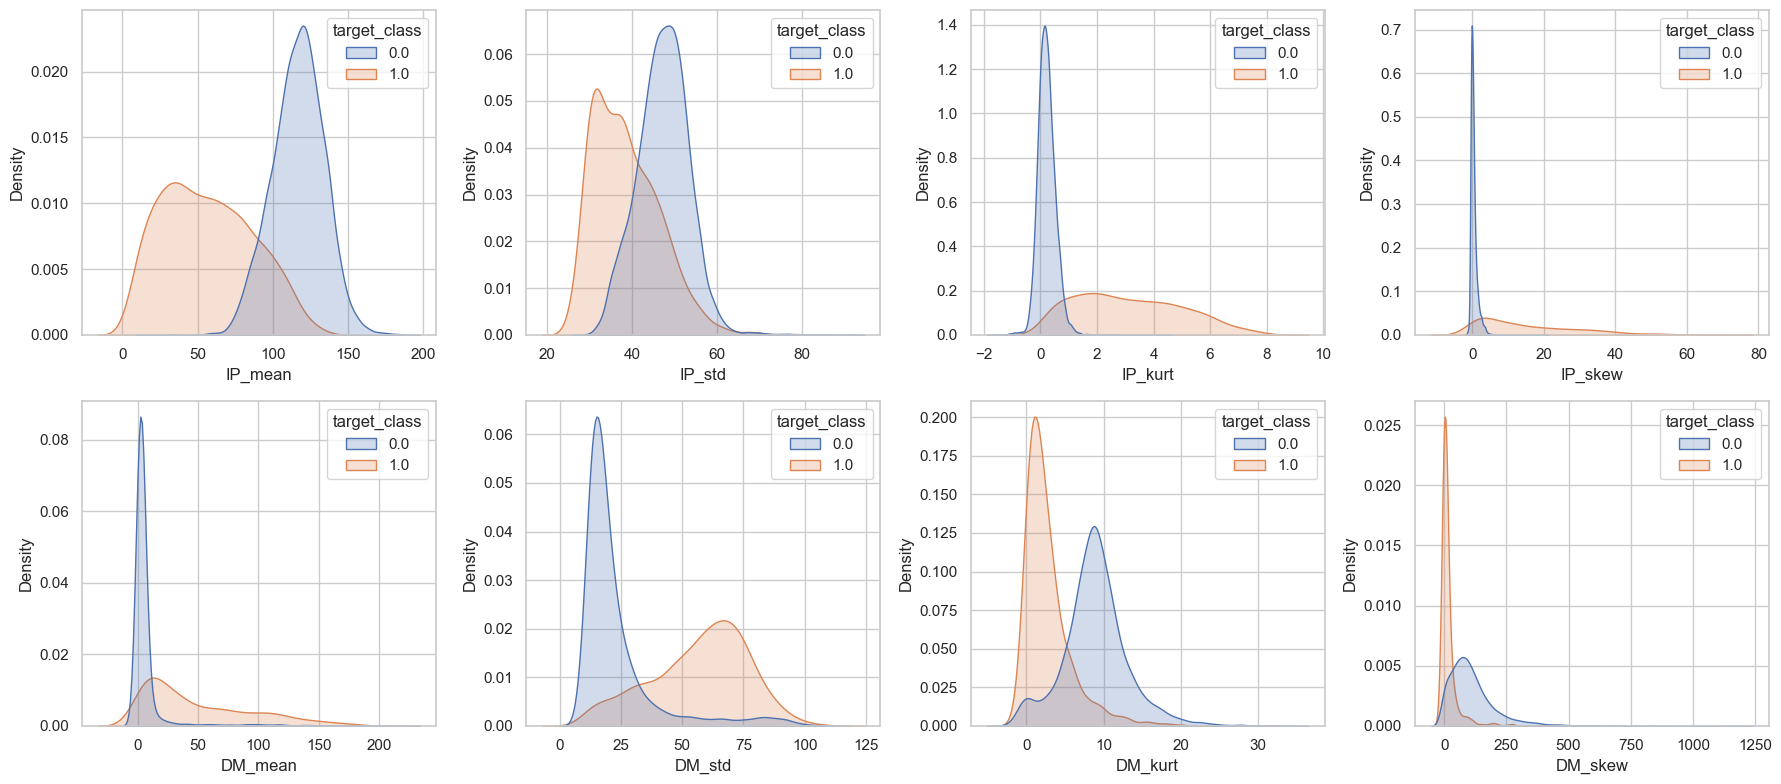

In [3]:
fitur = [c for c in train.columns if c!='target_class']
fig, axes = plt.subplots(2,4, figsize=(18,8))
for ax,c in zip(axes.ravel(), fitur):
    sns.kdeplot(data=train, x=c, hue='target_class', common_norm=False, fill=True, ax=ax)
plt.tight_layout(); plt.show()

**Cara membaca:** fitur dengan kurva yang berjauhan antara kelas 0 dan 1 adalah pembeda yang kuat. Pada data pulsar, biasanya statistik profil terintegrasi (terutama kurtosis dan skewness) paling membedakan.

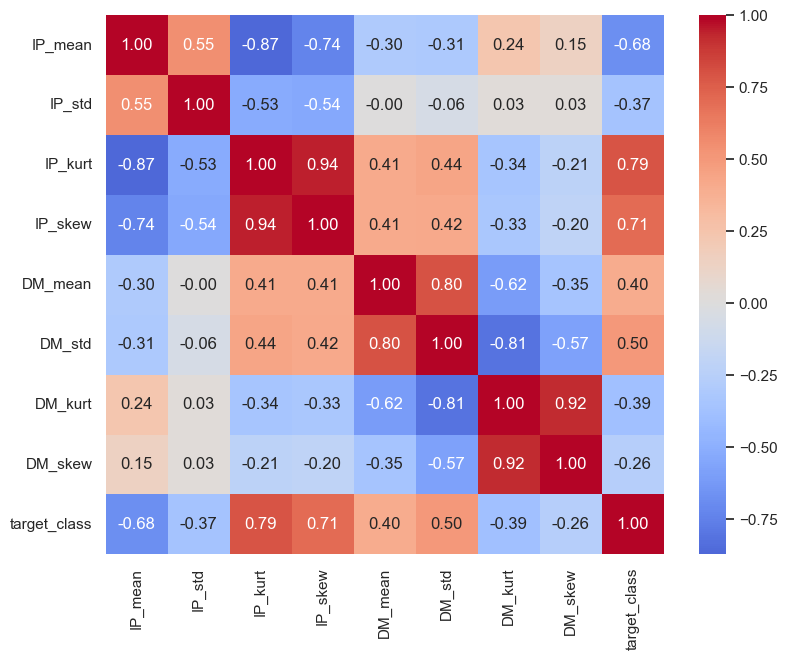

In [4]:
plt.figure(figsize=(9,7))
sns.heatmap(train.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0); plt.show()

## 2. Pemodelan (dengan penanganan *imbalance*)

In [5]:
lab = train.dropna(subset=['target_class'])
X, y = lab[fitur], lab['target_class'].astype(int)
Xtr, Xva, ytr, yva = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

models = {
 'Logistic Regression': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=1000, class_weight='balanced')),
 'Random Forest': make_pipeline(SimpleImputer(strategy='median'), RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42, n_jobs=-1)),
 'Gradient Boosting': HistGradientBoostingClassifier(class_weight='balanced', random_state=42),
}
rows = {}
for n,m in models.items():
    m.fit(Xtr, ytr); p = m.predict(Xva); pr = m.predict_proba(Xva)[:,1]
    rep = classification_report(yva, p, output_dict=True)['1']
    rows[n] = dict(precision=rep['precision'], recall=rep['recall'], f1=rep['f1-score'], ROC_AUC=roc_auc_score(yva,pr), PR_AUC=average_precision_score(yva,pr))
pd.DataFrame(rows).T.round(3)

,precision,recall,f1,ROC_AUC,PR_AUC
Logistic Regression,0.715,0.889,0.793,0.968,0.905
Random Forest,0.952,0.833,0.889,0.973,0.921
Gradient Boosting,0.887,0.896,0.891,0.980,0.926


Model terbaik (PR-AUC): Gradient Boosting
              precision    recall  f1-score   support

Bukan pulsar       0.99      0.99      0.99      2844
      Pulsar       0.89      0.90      0.89       288

    accuracy                           0.98      3132
   macro avg       0.94      0.94      0.94      3132
weighted avg       0.98      0.98      0.98      3132



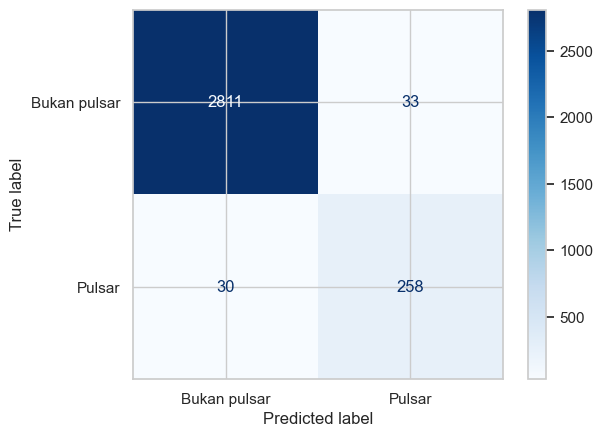

In [6]:
best_name = max(rows, key=lambda k: rows[k]['PR_AUC']); best = models[best_name]
print('Model terbaik (PR-AUC):', best_name)
p = best.predict(Xva)
print(classification_report(yva, p, target_names=['Bukan pulsar','Pulsar']))
ConfusionMatrixDisplay(confusion_matrix(yva,p), display_labels=['Bukan pulsar','Pulsar']).plot(cmap='Blues'); plt.show()

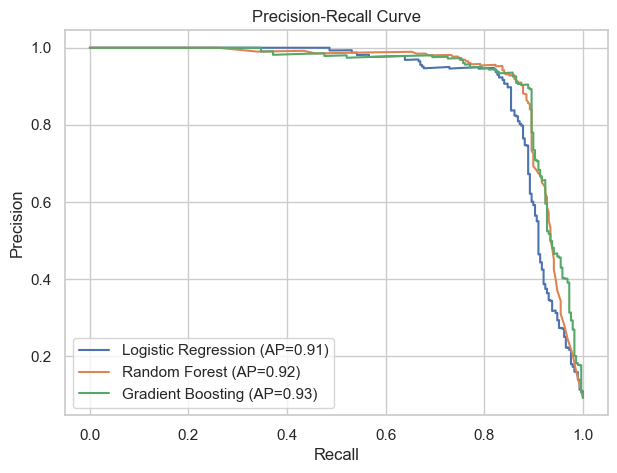

In [7]:
plt.figure(figsize=(7,5))
for n,m in models.items():
    pr, rc, _ = precision_recall_curve(yva, m.predict_proba(Xva)[:,1])
    plt.plot(rc, pr, label=f"{n} (AP={rows[n]['PR_AUC']:.2f})")
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Precision-Recall Curve'); plt.legend(); plt.show()

## 3. Prediksi pada Data Test (tanpa label)

In [8]:
best.fit(X, y)
test_pred = best.predict(test[fitur])
out = test.copy(); out['prediksi_pulsar'] = test_pred
print('Jumlah sinyal diprediksi pulsar:', out['prediksi_pulsar'].sum(), 'dari', len(out), f"({out['prediksi_pulsar'].mean():.1%})")
out.to_csv('hasil_prediksi_pulsar.csv', index=False)

Jumlah sinyal diprediksi pulsar: 569 dari 5370 (10.6%)


## 4. Kesimpulan
- Data tidak seimbang parah (± 9% pulsar) dan memiliki *missing value* di tiga fitur → ditangani dengan **imputasi median** dan **`class_weight='balanced'`**.
- Model dinilai dengan **recall dan precision kelas pulsar**. *Gradient Boosting* terbaik (PR-AUC ± 0,93; precision ± 0,89, recall ± 0,90). Random Forest lebih tinggi precision-nya (± 0,95) tetapi recall lebih rendah (± 0,83), sedangkan Logistic Regression banyak alarm palsu (precision ± 0,72).
- Pada data test, ± 10,6% sinyal diprediksi pulsar, tidak jauh dari proporsi di data latih (± 9,2%), sehingga hasilnya masuk akal. Karena label test tidak tersedia, akurasinya tidak bisa diverifikasi langsung.
- Hasil prediksi test disimpan di `hasil_prediksi_pulsar.csv`.